# Team 7 · Top materials: answering with a ranked list instead of one guess

**The problem.** A MINC patch is a small scene, but it has **one label**: the material at its centre. A carpet photo often also shows a wooden floor, so a "wood" match can be a sensible answer that our score counts as wrong. The user may also mean either surface.

**The idea (option 2).** The model stays the same. Only the **answer** changes: instead of "Carpet (3 of 5)" the app says **"Carpet 60% · Wood 40%"**.

**What this notebook measures**

| Question | Measure |
|---|---|
| How often is the right material **first**? | top-1 accuracy |
| How often is it **in the first 2 or 3** suggestions? | top-2, top-3 accuracy |
| Is it better to weight closer matches more, or use more neighbours? | 5 / 10 / 20 neighbours × plain / weighted votes |
| Can we trust the percentages? | accuracy for each confidence level (calibration) |
| How many suggestions should the app show? | coverage vs list length for a minimum share |

**Model:** the round-2 winner: DINOv2-small on the **centre crop** → our 32-number feature autoencoder → **cosine** distance. **Gallery:** 300 training patches per material (3,900), like the app. **Queries:** the 3,250 test patches.

**Needs:** the round-2 feature caches `data/minc_round2_*.npz` and the 64 px caches `data/minc64_*.npz` (made by the earlier notebooks).

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.neighbors import NearestNeighbors
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

AE_DIR = Path("..")
DATA_DIR = AE_DIR / ".." / "data"
FIG_DIR = AE_DIR / "figures"
RANDOM_STATE = 42
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
pd.set_option("display.float_format", "{:,.3f}".format)

ALL_CLASSES = ["brick", "carpet", "ceramic", "fabric", "foliage", "food", "glass", "hair", "leather",
               "metal", "mirror", "other", "painted", "paper", "plastic", "polishedstone", "skin", "sky",
               "stone", "tile", "wallpaper", "water", "wood"]
BUILDING = ["brick", "carpet", "ceramic", "glass", "metal", "mirror", "painted", "plastic",
            "polishedstone", "stone", "tile", "wallpaper", "wood"]
remap = {ALL_CLASSES.index(c): k for k, c in enumerate(BUILDING)}
N_CLASSES = len(BUILDING)


def save_fig(name):
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")


feats = {s: np.load(DATA_DIR / f"minc_round2_{s}.npz") for s in ["train", "test"]}
F_train, F_test = feats["train"]["dino_centre"], feats["test"]["dino_centre"]
y_train = np.array([remap[v] for v in feats["train"]["y"]])
y_test = np.array([remap[v] for v in feats["test"]["y"]])
img64 = {s: np.load(DATA_DIR / f"minc64_{s}.npz")["X"] for s in ["train", "test"]}
print(f"device {DEVICE} | train {F_train.shape} | test {F_test.shape}")

device mps | train (27625, 768) | test (3250, 768)


# 1. The model (same as round 2) and the app's gallery

The feature autoencoder is retrained exactly as in round 2 (denoising + weight decay, 30 epochs, seed 42): about 10 seconds. The gallery is **300 random training patches per material**, so every material has the same chance of being voted for.

In [2]:
class FeatureAE(nn.Module):
    def __init__(self, n_in, latent_dim=32, hidden=256):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(n_in, hidden), nn.ReLU(), nn.Linear(hidden, latent_dim))
        self.decoder = nn.Sequential(nn.Linear(latent_dim, hidden), nn.ReLU(), nn.Linear(hidden, n_in))

    def forward(self, x):
        return self.decoder(self.encoder(x))


mu, sd = F_train.mean(0), F_train.std(0) + 1e-6
Fs_train = ((F_train - mu) / sd).astype(np.float32)
Fs_test = ((F_test - mu) / sd).astype(np.float32)

torch.manual_seed(RANDOM_STATE)
ae = FeatureAE(Fs_train.shape[1]).to(DEVICE)
opt = torch.optim.AdamW(ae.parameters(), lr=1e-3, weight_decay=1e-4)
loader = DataLoader(TensorDataset(torch.from_numpy(Fs_train)), batch_size=256, shuffle=True,
                    generator=torch.Generator().manual_seed(RANDOM_STATE))
start = time.time()
for epoch in range(30):
    ae.train()
    for (x,) in loader:
        x = x.to(DEVICE)
        loss = nn.functional.mse_loss(ae(x + 0.5 * torch.randn_like(x)), x)
        opt.zero_grad(); loss.backward(); opt.step()
ae.eval()
print(f"trained in {time.time() - start:.0f} s")


@torch.no_grad()
def encode(F):
    Z = ae.encoder(torch.from_numpy(F).to(DEVICE)).cpu().numpy()
    return Z / np.linalg.norm(Z, axis=1, keepdims=True)          # length 1: Euclidean search = cosine search


Z_train, Z_test = encode(Fs_train), encode(Fs_test)

rng = np.random.default_rng(RANDOM_STATE)
gallery_idx = np.concatenate([rng.choice(np.flatnonzero(y_train == k), 300, replace=False) for k in range(N_CLASSES)])
Z_gal, y_gal = Z_train[gallery_idx], y_train[gallery_idx]
index = NearestNeighbors(n_neighbors=20).fit(Z_gal)
dist20, nbr20 = index.kneighbors(Z_test)                         # the 20 nearest gallery patches per test patch
print(f"gallery {Z_gal.shape}, neighbours {nbr20.shape}")

trained in 9 s
gallery (3900, 32), neighbours (3250, 20)


# 2. From neighbours to a ranked list of materials

For each test photo we turn its k nearest gallery patches into a score per material:

- **plain votes:** every neighbour counts 1;
- **weighted votes:** a neighbour counts **1 / distance**, so a very close match counts more than a far one.

Each material's **share** = its score / the total. The list is sorted by share; a tie goes to the material with the closest single match.

In [3]:
def ranked_materials(dist, nbr, k=5, weighted=False):
    # -> shares (n_queries, 13) and the material order (n_queries, 13), best first
    d, labels = dist[:, :k], y_gal[nbr[:, :k]]
    w = 1.0 / (d + 1e-6) if weighted else np.ones_like(d)
    scores = np.zeros((len(d), N_CLASSES))
    closest = np.full((len(d), N_CLASSES), np.inf)
    rows = np.arange(len(d))[:, None]
    np.add.at(scores, (rows, labels), w)
    np.minimum.at(closest, (rows, labels), d)
    shares = scores / scores.sum(1, keepdims=True)
    tie_break = np.where(np.isinf(closest), 0, closest)         # among equal shares, the closer match wins
    order = np.argsort(-(shares - 1e-6 * tie_break), axis=1, kind="stable")
    return shares, order


def top_k_accuracy(shares, order, y, k):
    # the true material is among the first k suggestions (and was actually voted for)
    picked = order[:, :k]
    voted = np.take_along_axis(shares, picked, 1) > 0
    return ((picked == y[:, None]) & voted).any(1).mean()


rows = []
for k in [5, 10, 20]:
    for weighted in [False, True]:
        shares, order = ranked_materials(dist20, nbr20, k, weighted)
        rows.append({"neighbours": k, "votes": "weighted" if weighted else "plain",
                     "top-1": top_k_accuracy(shares, order, y_test, 1),
                     "top-2": top_k_accuracy(shares, order, y_test, 2),
                     "top-3": top_k_accuracy(shares, order, y_test, 3),
                     "materials voted for (avg)": (shares > 0).sum(1).mean()})
methods = pd.DataFrame(rows)
methods.to_csv(AE_DIR / "results_top_materials.csv", index=False)
methods

,neighbours,votes,top-1,top-2,top-3,materials voted for (avg)
0,5,plain,0.698,0.812,0.846,2.124
1,5,weighted,0.698,0.812,0.846,2.124
2,10,plain,0.710,0.835,0.878,2.943
3,10,weighted,0.711,0.837,0.878,2.943
4,20,plain,0.717,0.846,0.898,4.070
5,20,weighted,0.717,0.847,0.897,4.070


Figure saved to ../figures/15_top_materials_accuracy.png


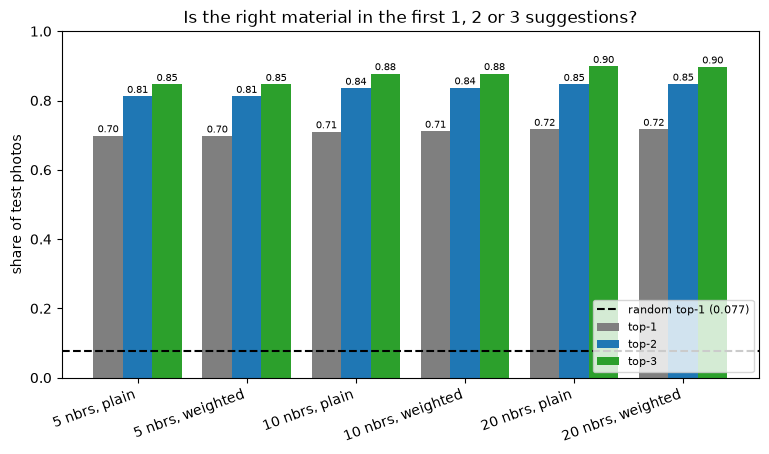

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
labels = [f"{r.neighbours} nbrs, {r.votes}" for r in methods.itertuples()]
x = np.arange(len(methods))
for j, (col, colour) in enumerate([("top-1", "tab:gray"), ("top-2", "tab:blue"), ("top-3", "tab:green")]):
    ax.bar(x + (j - 1) * 0.27, methods[col], width=0.27, label=col, color=colour)
    for xi, v in zip(x, methods[col]):
        ax.text(xi + (j - 1) * 0.27, v + 0.01, f"{v:.2f}", ha="center", fontsize=7)
ax.axhline(1 / 13, color="black", linestyle="--", label="random top-1 (0.077)")
ax.set_xticks(x, labels, rotation=20, ha="right")
ax.set_ylim(0, 1); ax.set_ylabel("share of test photos")
ax.set_title("Is the right material in the first 1, 2 or 3 suggestions?")
ax.legend(loc="lower right", fontsize=8)
save_fig("15_top_materials_accuracy")
plt.show()

# 3. Can we trust the percentages? (calibration)

If the app says "Carpet 80%", the first guess should be right about 80% of the time. We group the test photos by the share of their **first** suggestion and check how often that first suggestion was right. With plain votes from 5 neighbours the share can only be 20%, 40%, 60%, 80% or 100%.

Figure saved to ../figures/16_top_materials_calibration.png


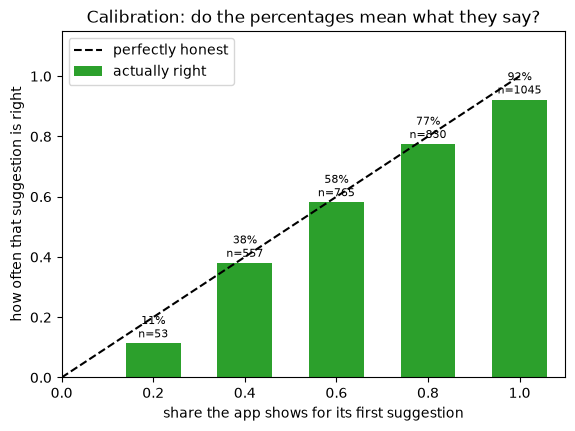

first share,0.200,0.400,0.600,0.800,1.000
actually right,0.113,0.381,0.582,0.775,0.922
photos,53.000,557.000,765.000,830.000,"1,045.000"


In [5]:
K, WEIGHTED = 5, False                       # the app's current setting; change to compare
shares, order = ranked_materials(dist20, nbr20, K, WEIGHTED)
top_share = shares[np.arange(len(shares)), order[:, 0]]
correct = order[:, 0] == y_test
calib = (pd.DataFrame({"first share": np.round(top_share, 1), "right": correct})
         .groupby("first share")["right"].agg(["mean", "size"])
         .rename(columns={"mean": "actually right", "size": "photos"}))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.bar(calib.index, calib["actually right"], width=0.12, color="tab:green", label="actually right")
ax.plot([0, 1], [0, 1], "k--", label="perfectly honest")
for s, r in calib.iterrows():
    ax.text(s, r["actually right"] + 0.02, f"{r['actually right']:.0%}\nn={int(r['photos'])}", ha="center", fontsize=8)
ax.set_xlabel("share the app shows for its first suggestion"); ax.set_ylabel("how often that suggestion is right")
ax.set_xlim(0, 1.1); ax.set_ylim(0, 1.15); ax.legend(loc="upper left")
ax.set_title("Calibration: do the percentages mean what they say?")
save_fig("16_top_materials_calibration")
plt.show()
calib.T

# 4. How many suggestions should the app show?

A simple rule: show every material with **at least a minimum share**, at most 3. A low minimum shows more suggestions and catches the right one more often; a high minimum keeps the answer short.

In [6]:
rule = []
for min_share in [0.2, 0.3, 0.4, 0.5]:
    shown = np.take_along_axis(shares, order[:, :3], 1) >= min_share
    shown[:, 0] = True                                       # always show at least the first suggestion
    hit = ((order[:, :3] == y_test[:, None]) & shown).any(1)
    rule.append({"minimum share": min_share, "right material shown": hit.mean(),
                 "suggestions shown (avg)": shown.sum(1).mean(),
                 "only 1 shown": (shown.sum(1) == 1).mean()})
pd.DataFrame(rule)

,minimum share,right material shown,suggestions shown (avg),only 1 shown
0,0.200,0.846,2.006,0.322
1,0.300,0.752,1.181,0.819
2,0.400,0.752,1.181,0.819
3,0.500,0.698,1.000,1.000


In [7]:
# Per material: first suggestion vs anywhere in the top 3 (5 neighbours, plain votes)
per = pd.DataFrame({
    "top-1": pd.Series(order[:, 0] == y_test).groupby(y_test).mean().values,
    "top-3": pd.Series(((order[:, :3] == y_test[:, None]) &
                        (np.take_along_axis(shares, order[:, :3], 1) > 0)).any(1)).groupby(y_test).mean().values,
}, index=BUILDING).sort_values("top-3")
per["gain"] = per["top-3"] - per["top-1"]
per.T

,metal,wood,mirror,polishedstone,tile,painted,plastic,glass,wallpaper,ceramic,carpet,stone,brick
top-1,0.456,0.608,0.604,0.692,0.652,0.648,0.716,0.680,0.804,0.760,0.840,0.788,0.832
top-3,0.716,0.760,0.768,0.820,0.832,0.840,0.844,0.860,0.872,0.900,0.924,0.932,0.936
gain,0.260,0.152,0.164,0.128,0.180,0.192,0.128,0.180,0.068,0.140,0.084,0.144,0.104


# 5. What the user would see

The same test photos as the round-2 similarity figure, with the ranked answer the app would give.

Figure saved to ../figures/17_top_materials_examples.png


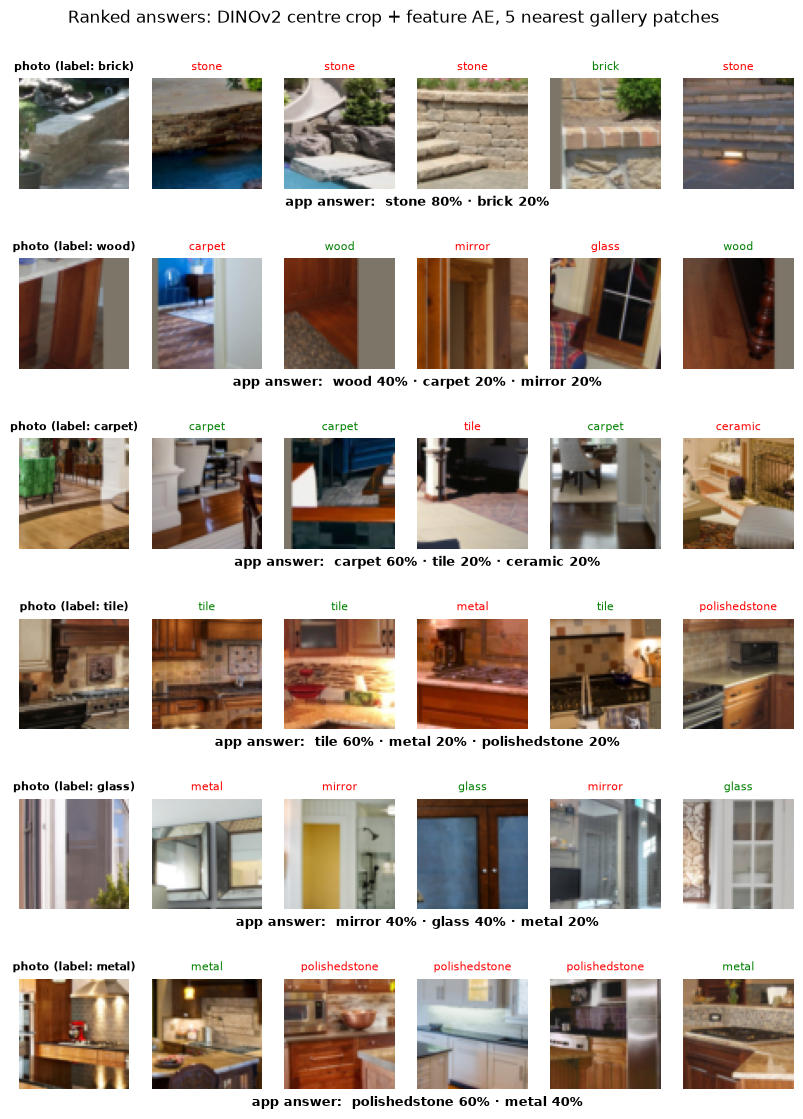

In [8]:
def answer_text(i, min_share=0.2):
    parts = [f"{BUILDING[c]} {shares[i, c]:.0%}" for c in order[i, :3] if shares[i, c] >= min_share]
    return " · ".join(parts)


SHOW = ["brick", "wood", "carpet", "tile", "glass", "metal"]
queries = [int(np.flatnonzero(y_test == BUILDING.index(m))[3]) for m in SHOW]
fig, axes = plt.subplots(len(SHOW), 6, figsize=(10, 2.2 * len(SHOW)), gridspec_kw={"hspace": 0.55})
for r, q in enumerate(queries):
    axes[r, 0].imshow(img64["test"][q])
    axes[r, 0].set_title(f"photo (label: {BUILDING[y_test[q]]})", fontsize=8, fontweight="bold")
    for c in range(5):
        g = nbr20[q, c]
        axes[r, c + 1].imshow(img64["train"][gallery_idx[g]])
        axes[r, c + 1].set_title(BUILDING[y_gal[g]], fontsize=8,
                                 color="green" if y_gal[g] == y_test[q] else "red")
    for a in axes[r]:
        a.axis("off")
    axes[r, 3].text(0.0, -0.06, "app answer:  " + answer_text(q), transform=axes[r, 3].transAxes,
                    ha="center", va="top", fontsize=9, fontweight="bold")
plt.suptitle("Ranked answers: DINOv2 centre crop + feature AE, 5 nearest gallery patches", y=0.93)
save_fig("17_top_materials_examples")
plt.show()

Figure saved to ../figures/18_centre_crop_similarity.png


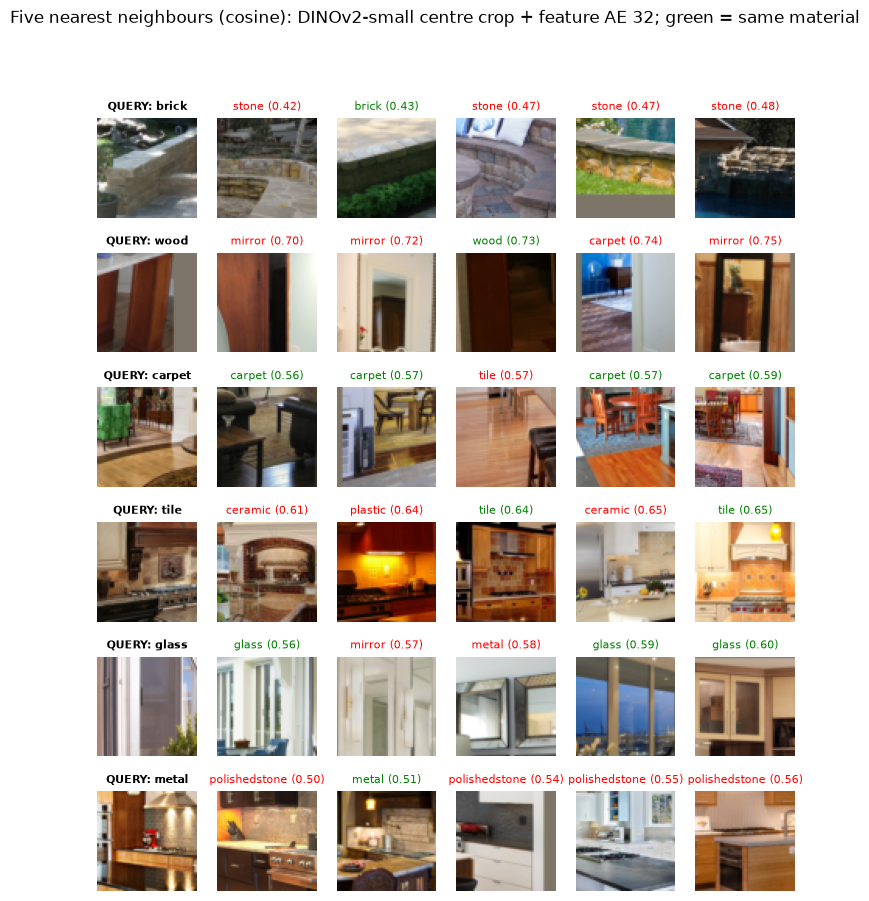

In [ ]:
# Proof figure for the chosen model: 5 nearest of ALL training patches (as precision@5 is measured), cosine
full_index = NearestNeighbors(n_neighbors=5).fit(Z_train)
dist_f, nbr_f = full_index.kneighbors(Z_test[queries])
fig, axes = plt.subplots(len(SHOW), 6, figsize=(9, 1.7 * len(SHOW)))
for r, q in enumerate(queries):
    axes[r, 0].imshow(img64["test"][q]); axes[r, 0].set_title(f"QUERY: {BUILDING[y_test[q]]}", fontsize=8, fontweight="bold")
    for c in range(5):
        i = nbr_f[r, c]
        axes[r, c + 1].imshow(img64["train"][i])
        axes[r, c + 1].set_title(f"{BUILDING[y_train[i]]} ({dist_f[r, c]:.2f})", fontsize=8,
                                 color="green" if y_train[i] == y_test[q] else "red")
    for a in axes[r]:
        a.axis("off")
plt.suptitle("Five nearest neighbours (cosine): DINOv2-small centre crop + feature AE 32; green = same material")
save_fig("18_centre_crop_similarity")
plt.show()

# 6. The server's reply format (for Tuesday)

The ranked list replaces the single `material_guess`. `material_guess` and `confidence` stay as the first item, so the app on Wednesday can use either.

In [9]:
import json

q = queries[SHOW.index("carpet")]
reply = {
    "material_guess": BUILDING[order[q, 0]],
    "confidence": round(float(shares[q, order[q, 0]]), 2),
    "materials": [{"name": BUILDING[c], "share": round(float(shares[q, c]), 2)}
                  for c in order[q, :3] if shares[q, c] >= 0.2],
    "matches": [{"id": int(gallery_idx[g]), "material": BUILDING[y_gal[g]], "distance": round(float(d), 3)}
                for g, d in zip(nbr20[q, :5], dist20[q, :5])],
}
print(json.dumps(reply, indent=2))

{
  "material_guess": "carpet",
  "confidence": 0.6,
  "materials": [
    {
      "name": "carpet",
      "share": 0.6
    },
    {
      "name": "tile",
      "share": 0.2
    },
    {
      "name": "ceramic",
      "share": 0.2
    }
  ],
  "matches": [
    {
      "id": 2704,
      "material": "carpet",
      "distance": 0.631
    },
    {
      "id": 3831,
      "material": "carpet",
      "distance": 0.663
    },
    {
      "id": 22933,
      "material": "tile",
      "distance": 0.676
    },
    {
      "id": 4209,
      "material": "carpet",
      "distance": 0.701
    },
    {
      "id": 5517,
      "material": "ceramic",
      "distance": 0.702
    }
  ]
}


# 7. What we conclude

Model: DINOv2-small centre crop → AE 32 → cosine. Gallery 3,900 patches (300 per material), 3,250 test photos.

**How much higher is top-3 than top-1? The slide headline**
- With 5 neighbours and plain votes: **top-1 0.698, top-2 0.812, top-3 0.846**. The ranked list adds **+15 points** over a single guess.
- For comparison, picking 3 materials at random would be right 3/13 = 23% of the time.
- **Slide headline:** *"The right material is in our top 3 suggestions 85% of the time, and it is our first guess 70% of the time."*

**Do weighted votes or more neighbours help, or is plain 5-neighbour voting enough?**
- **Weighted votes make no difference** (5 neighbours: 0.698 vs 0.698; 10: 0.710 vs 0.711; 20: 0.717 vs 0.717). The 5 nearest matches are at very similar cosine distances, so weighting by 1 / distance hardly changes the order.
- **More neighbours help a little:** 20 neighbours give top-1 0.717 (+0.019) and top-3 0.898 (+0.052). But the votes spread over more materials (4.1 on average instead of 2.1), so every share gets smaller and the answer sounds less sure.
- **Plain 5-neighbour voting is enough.** It is the simplest, it matches the 5 thumbnails the app already shows (the user can count the votes), and the gain from more neighbours is small.

**Are the percentages honest? When should the app sound sure?**
- **Mostly yes, slightly over-confident at the top:**

| App says (first suggestion) | Actually right | Photos |
|---|---|---|
| 100% (5 of 5) | 92% | 1,045 |
| 80% (4 of 5) | 78% | 830 |
| 60% (3 of 5) | 58% | 765 |
| 40% (2 of 5) | 38% | 557 |
| 20% (1 of 5) | 11% | 53 |

- Each level is a few points over-confident, most at 20% (says 20%, right 11%) and at 100% (says 100%, right 92%). Never show "100%": say **"very likely"**.
- **Sound sure at 80% or more** (4 or 5 of 5 votes): right 78–92% of the time, and this covers 58% of the photos.
- **Say "could be X or Y" at 60% or less**: at 40% the first guess is wrong more often than right.

**Which minimum share for the app, and why?**

| Minimum share | Right material shown | Suggestions shown (avg) |
|---|---|---|
| 20% | **84.6%** | 2.0 |
| 30% or 40% | 75.2% | 1.2 |
| 50% | 69.8% | 1.0 |

- **We use 20%**, with at most 3 suggestions. It shows the right material 85% of the time, with only 2 suggestions on average, and 32% of the photos still get a single, confident answer.
- Raising it to 30% or 40% loses almost 10 points of coverage to save less than one suggestion.
- 30% and 40% give the same result: with 5 votes the shares can only be 20%, 40%, 60%… so any minimum between 20% and 40% behaves like 40%.

**Which materials gain most from a ranked answer? Does that match the "mixed scene" idea?**
- Biggest gains from top-1 to top-3: **metal +0.26** (0.46 → 0.72), **painted +0.19**, **tile +0.18**, **glass +0.18**, **mirror +0.16**, **wood +0.15**, **stone +0.14**, **ceramic +0.14**.
- **Partly yes.** Tile (kitchens, bathrooms, next to ceramic) and wood (floors under carpet, furniture) fit the mixed-scene idea. Metal, glass and mirror gain most because they **reflect** their surroundings, so their neighbours show what is around them, and the right label often comes 2nd.
- **Carpet gains little** (+0.08): it is already right first 84% of the time. Its wrong answers are often wood or tile, the floor around it.
- Materials that are already strong (brick 0.83, carpet 0.84, wallpaper 0.80) gain the least: their first guess is already right.

**Remember:** this changes the **answer**, not the model. When the first guess is "wood" for a photo labelled "carpet", the photo often really shows a carpet on a wooden floor: MINC's single label calls it wrong, but a user might not. The 85% top-3 figure is closer to what a user experiences than the 70% top-1.

# 8. Presentation: three slides

The three cells below are a short presentation of the whole week's model work (all four notebooks). They are marked as slides: run `jupyter nbconvert top_materials.ipynb --to slides --post serve` from the `notebook/` folder to present them, or just scroll through them here.

## Slide 1 · What we did: from pixels to a ranked answer

**Goal:** a user photographs a surface (facade, floor, wall). The app returns the **5 most similar material patches**, a **material guess**, and a warning if the photo is **not a building material**.
**Data:** MINC-2500, 13 building materials, 27,625 training patches; the 10 other classes only for the "unusual" test. **Rule:** the autoencoder never sees a MINC label; labels are only used to *measure*.

| Step | Notebook | What we tried | Search quality (precision@5) |
|---|---|---|---|
| 1 | `autoencoder` | Pixel autoencoders on 64 px patches: dense vs conv, code of 32 vs 128 | 0.13 → **0.14** |
| 2 | `improvements` | More pixels · regularisers · **frozen ResNet-18 in front** of a small AE | 0.14 → **0.41** |
| 3 | `improvements_round2` | Cosine distance · centre crop · texture (Gram) · **DINOv2-small** · TTA | 0.41 → **0.65** |
| 4 | `top_materials` | Same model; the answer becomes a **ranked list** of materials | first guess **70%**, top 3 **85%** |

Random guessing: precision@5 = 1/13 ≈ 0.08. Same split, seed and metric at every step.

**Final pipeline:** photo → centre crop → DINOv2-small (768 features) → our autoencoder (**32 numbers**) → cosine distance to 3,900 gallery patches → 5 nearest → votes → *"Carpet 60% · Tile 20% · Ceramic 20%"*

## Slide 2 · What we found

<img src="../figures/12_round2_precision.png" width="480" align="right">

**1. A pixel autoencoder learns colour, not material.** At 64 px, brick joints and wood grain are already gone. Reconstructions are colour blobs; matches follow colour and grey padding. Better reconstruction (latent 128) did **not** give better search.

**2. Pretrained features did the heavy lifting.** ResNet-18 tripled search quality (0.14 → 0.41). More pixels (128 px, zoom) and regularisers changed less than ±0.01.

**3. MINC patches are scenes; the label is the centre.** Cropping to the centre helped every network (DINOv2: +0.065) and gave the best "unusual photo" score (AUC 0.65 → **0.82**).

**4. DINOv2 > ResNet-18 > Gram texture.** Self-supervised DINOv2 beat ResNet by about +0.15; texture-only Gram features were the worst. Cosine distance adds +0.01 to +0.03 for free. Test-time augmentation was not worth 3× the compute.

**5. Our 32-number code costs almost nothing:** 768 → 32 numbers (24× smaller), precision@5 0.661 → 0.647.

**6. A ranked answer is honest and useful.** The right material is first 70% of the time and in the top 3 **85%**. The percentages are roughly calibrated (says 80%, right 78%). Reflective materials gain most (metal +26 points).

## Slide 3 · What we conclude

**For the app**
- Ship **DINOv2-small, centre crop → AE 32 → cosine**, with **5 neighbours, plain votes**, showing every material with **≥ 20%** (max 3).
- Sound sure only at **≥ 80%** ("very likely carpet"); below that, say **"could be X or Y"**. Never show "100%" (it is right 92% of the time).
- The "unusual photo" warning is a **hint, not a verdict**: AUC 0.82 is useful, not reliable.
- Ask users to photograph the surface **close up**: that is what the centre crop rewards.

**Limitations (honestly)**
- **Metal, wood and glass stay weakest** (top-1 46–68%): reflections and very different scenes.
- MINC gives **one label per scene**: some "wrong" answers (wood under a carpet) are sensible. Our 70% understates what a user experiences.
- Most of the gain comes from **DINOv2's pretrained features**, not from our autoencoder. Our AE compresses them 24× for fast search.
- DINOv2 is an 88 MB model: it should fit Render's free server (512 MB RAM), but we must **measure** it. Fallback: ResNet-18 + centre crop (0.47, 45 MB).
- Not yet tested on **our own phone photos**.

**Headline:** *the right material is in our top 3 suggestions 85% of the time, from a model that never saw a material label.*